# Customer Churn Prediction

In this project I am trying to predict whether a telecom customer will leave the company (churn) or stay. I am using the Telco Customer Churn dataset, which has 7043 customers and 21 columns about their services, billing and contract.

The plan is simple: clean the data, explore it, build a few classification models, and finally make a small Streamlit app so anyone can try it.


## 1. Importing Libraries and Loading Data

First I will import the libraries I need for this project. After that I will load the dataset and have a first look at it.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully")

Libraries imported successfully


In [2]:
df = pd.read_csv('../data/telco_churn.csv')

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

## 2. Data Cleaning

While checking the info I noticed that TotalCharges is stored as text instead of a number. I will fix that first and then check for missing values.

In [4]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

df['TotalCharges'].isnull().sum()

np.int64(11)

In [5]:
df[df['TotalCharges'].isnull()]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No


In [6]:
df = df.dropna(subset=['TotalCharges'])

df.shape

(7032, 21)

In [7]:
df = df.drop('customerID', axis=1)

df.shape

(7032, 20)

df.duplicated().sum()

## 3. Exploratory Data Analysis (EDA)

The data is clean now, so I will explore it to understand what kind of customers are leaving. I will start with the target column, Churn, and see how many customers actually churned.

In [10]:
print(df['Churn'].value_counts())
print()
print(df['Churn'].value_counts(normalize=True) * 100)

Churn
No     5163
Yes    1869
Name: count, dtype: int64

Churn
No     73.421502
Yes    26.578498
Name: proportion, dtype: float64


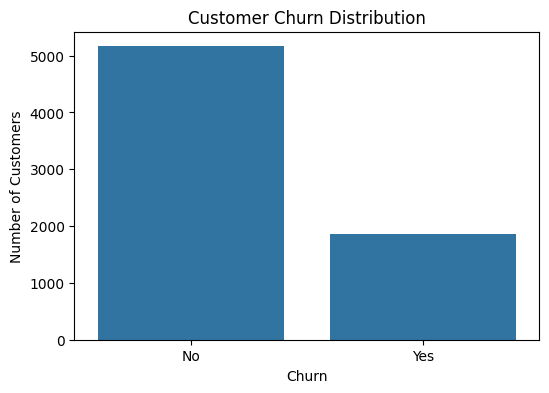

In [11]:
plt.figure(figsize=(6, 4))
sns.countplot(x='Churn', data=df)
plt.title('Customer Churn Distribution')
plt.xlabel('Churn')
plt.ylabel('Number of Customers')
plt.savefig('../images/churn_distribution.png', bbox_inches='tight')
plt.show()

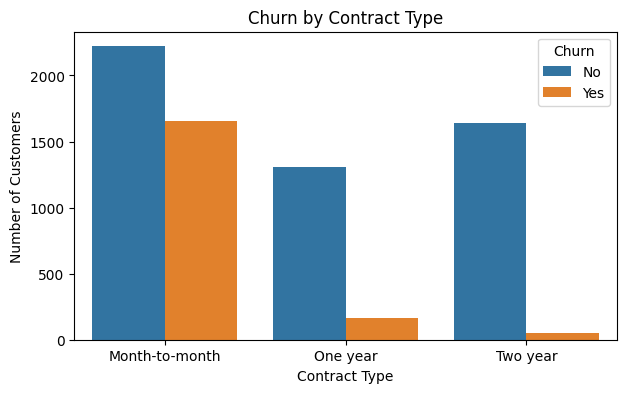

In [12]:
plt.figure(figsize=(7, 4))
sns.countplot(x='Contract', hue='Churn', data=df)
plt.title('Churn by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Number of Customers')
plt.savefig('../images/churn_by_contract.png', bbox_inches='tight')
plt.show()

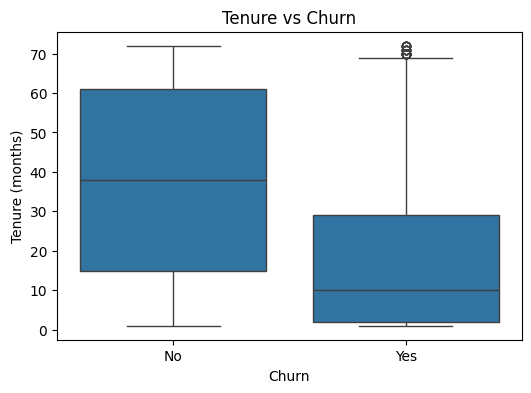

In [13]:
plt.figure(figsize=(6, 4))
sns.boxplot(x='Churn', y='tenure', data=df)
plt.title('Tenure vs Churn')
plt.xlabel('Churn')
plt.ylabel('Tenure (months)')
plt.savefig('../images/tenure_vs_churn.png', bbox_inches='tight')
plt.show()

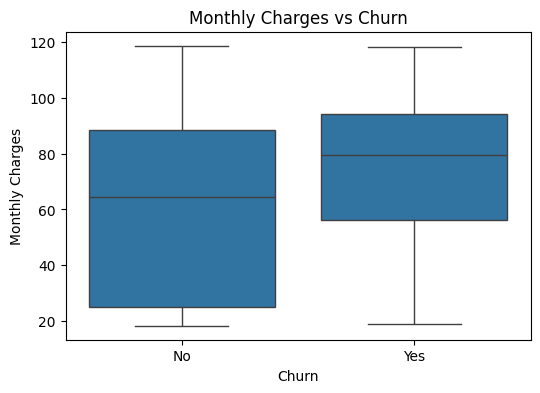

In [16]:
plt.figure(figsize=(6, 4))
sns.boxplot(x='Churn', y='MonthlyCharges', data=df)
plt.title('Monthly Charges vs Churn')
plt.xlabel('Churn')
plt.ylabel('Monthly Charges')
plt.savefig('../images/monthlycharges_vs_churn.png', bbox_inches='tight')
plt.show()

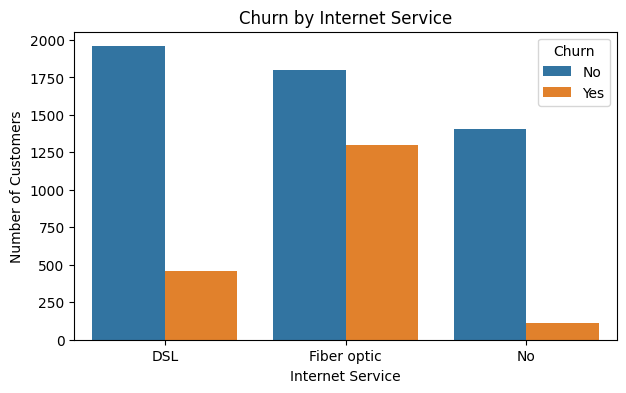

In [17]:
plt.figure(figsize=(7, 4))
sns.countplot(x='InternetService', hue='Churn', data=df)
plt.title('Churn by Internet Service')
plt.xlabel('Internet Service')
plt.ylabel('Number of Customers')
plt.savefig('../images/churn_by_internet.png', bbox_inches='tight')
plt.show()

### Key Findings from EDA

After looking at all the charts, these are the main things I noticed:

- The data is imbalanced. Around 73% customers stayed and only 27% churned, so accuracy alone will not be a good metric.
- Customers on a month-to-month contract churn the most. Very few customers with one or two year contracts leave.
- Churn happens mostly in the early months. The median tenure of churned customers is around 10 months, while for customers who stayed it is around 38 months.
- Customers who pay a higher monthly bill are more likely to churn.
- Fiber optic users churn much more than DSL users or customers without internet.

So the customers at highest risk are new, month-to-month customers with a high bill and a fiber optic connection.

## 4. Data Preparation

Machine learning models only understand numbers, so I need to convert the text columns into numeric form. I will start with the target column Churn and then handle the other categorical columns.

In [18]:
df['Churn'] = df['Churn'].map({'No': 0, 'Yes': 1})

df['Churn'].value_counts()

Churn
0    5163
1    1869
Name: count, dtype: int64

In [19]:
cat_cols = df.select_dtypes(exclude='number').columns

print(list(cat_cols))
print(len(cat_cols))

['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
15


In [20]:
df_encoded = pd.get_dummies(df, columns=cat_cols, drop_first=True, dtype=int)

df_encoded.shape

(7032, 31)

In [21]:
df_encoded.head()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,0,1,0,0,1,...,0,0,0,0,0,0,1,0,1,0
1,0,34,56.95,1889.50,0,1,0,0,1,0,...,0,0,0,0,1,0,0,0,0,1
2,0,2,53.85,108.15,1,1,0,0,1,0,...,0,0,0,0,0,0,1,0,0,1
3,0,45,42.30,1840.75,0,1,0,0,0,1,...,0,0,0,0,1,0,0,0,0,0
4,0,2,70.70,151.65,1,0,0,0,1,0,...,0,0,0,0,0,0,1,0,1,0


In [22]:
X = df_encoded.drop('Churn', axis=1)
y = df_encoded['Churn']

print(X.shape)
print(y.shape)

(7032, 30)
(7032,)


In [24]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(X_train.shape)
print(X_test.shape)

(5625, 30)
(1407, 30)


In [25]:
from sklearn.preprocessing import StandardScaler

num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

X_train[num_cols].head()

,tenure,MonthlyCharges,TotalCharges
1413,1.321816,0.981556,1.659900
7003,-0.267410,-0.971546,-0.562252
3355,1.444064,0.837066,1.756104
4494,-1.204646,0.641092,-0.908326
3541,0.669826,-0.808787,-0.101561


## 5. Model Building

The data is ready, so now I will train the models. I am starting with Logistic Regression as a simple baseline model, and later I will compare it with other models like Random Forest.

In [26]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

log_model = LogisticRegression(max_iter=1000, random_state=42)
log_model.fit(X_train, y_train)

y_pred = log_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.8045486851457001


In [27]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1033
           1       0.65      0.57      0.61       374

    accuracy                           0.80      1407
   macro avg       0.75      0.73      0.74      1407
weighted avg       0.80      0.80      0.80      1407



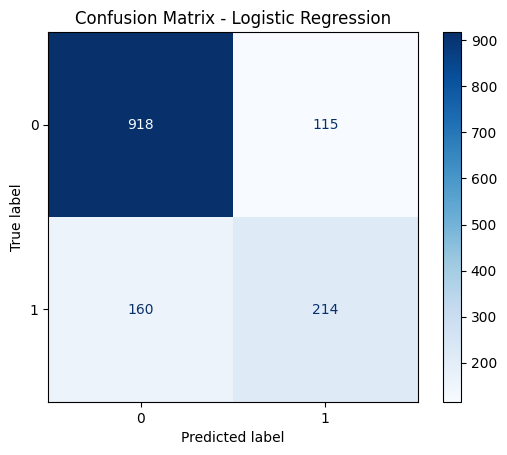

In [28]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap='Blues')
plt.title('Confusion Matrix - Logistic Regression')
plt.savefig('../images/confusion_matrix_logistic.png', bbox_inches='tight')
plt.show()

In [29]:
log_model_bal = LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced')
log_model_bal.fit(X_train, y_train)

y_pred_bal = log_model_bal.predict(X_test)

print(classification_report(y_test, y_pred_bal))

              precision    recall  f1-score   support

           0       0.90      0.70      0.79      1033
           1       0.49      0.79      0.61       374

    accuracy                           0.73      1407
   macro avg       0.70      0.75      0.70      1407
weighted avg       0.79      0.73      0.74      1407



In [30]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')
rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

           0       0.87      0.80      0.84      1033
           1       0.55      0.67      0.60       374

    accuracy                           0.77      1407
   macro avg       0.71      0.73      0.72      1407
weighted avg       0.78      0.77      0.77      1407



In [32]:
!pip install xgboost

  Using cached xgboost-3.4.1-py3-none-win_amd64.whl.metadata (2.0 kB)
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.5/48.9 MB 1.2 MB/s eta 0:00:42
    --------------------------------------- 1.0/48.9 MB 1.5 MB/s eta 0:00:33
    --------------------------------------- 1.0/48.9 MB 1.5 MB/s eta 0:00:33
    --------------------------------------- 1.0/48.9 MB 1.5 MB/s eta 0:00:33
   - -------------------------------------- 1.3/48.9 MB 890.2 


[notice] A new release of pip is available: 26.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [33]:
from xgboost import XGBClassifier

scale_weight = (y_train == 0).sum() / (y_train == 1).sum()

xgb_model = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    scale_pos_weight=scale_weight,
    random_state=42,
    eval_metric='logloss'
)
xgb_model.fit(X_train, y_train)

y_pred_xgb = xgb_model.predict(X_test)

print(classification_report(y_test, y_pred_xgb))

              precision    recall  f1-score   support

           0       0.91      0.70      0.79      1033
           1       0.50      0.80      0.61       374

    accuracy                           0.73      1407
   macro avg       0.70      0.75      0.70      1407
weighted avg       0.80      0.73      0.74      1407



In [34]:
from sklearn.metrics import roc_auc_score

models = {
    'Logistic Regression': log_model,
    'Logistic Regression (balanced)': log_model_bal,
    'Random Forest (balanced)': rf_model,
    'XGBoost': xgb_model
}

for name, model in models.items():
    prob = model.predict_proba(X_test)[:, 1]
    print(name, "-> ROC-AUC:", round(roc_auc_score(y_test, prob), 3))

Logistic Regression -> ROC-AUC: 0.836
Logistic Regression (balanced) -> ROC-AUC: 0.835
Random Forest (balanced) -> ROC-AUC: 0.82
XGBoost -> ROC-AUC: 0.84


## 7. Final Model and Feature Importance

XGBoost gave the best ROC-AUC and the best recall for churn customers, so I am choosing it as my final model. Now I will check which features it used the most to make its predictions.

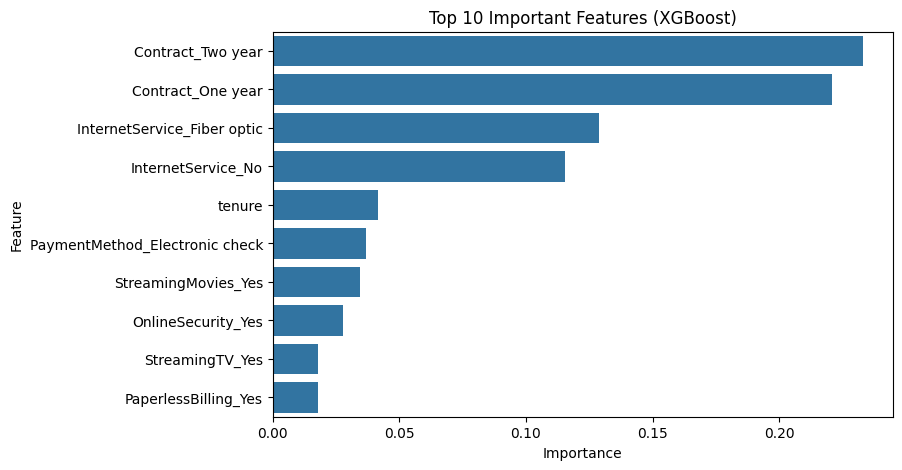

In [35]:
importances = pd.Series(xgb_model.feature_importances_, index=X.columns)
top10 = importances.sort_values(ascending=False).head(10)

plt.figure(figsize=(8, 5))
sns.barplot(x=top10.values, y=top10.index)
plt.title('Top 10 Important Features (XGBoost)')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.savefig('../images/feature_importance.png', bbox_inches='tight')
plt.show()

## 8. Saving the Model

The model is final, so I am saving it along with the scaler and the column names. These three files will be used in the Streamlit app to predict churn for a new customer.

In [37]:
import joblib
import os

joblib.dump(xgb_model, '../models/churn_model.pkl')
joblib.dump(scaler, '../models/scaler.pkl')
joblib.dump(X.columns.tolist(), '../models/columns.pkl')

print(os.listdir('../models'))

['churn_model.pkl', 'columns.pkl', 'scaler.pkl']


## 9. Conclusion

In this project I built a model to predict whether a telecom customer will churn. After cleaning the data and exploring it, I trained four models and compared them. XGBoost gave the best result, with a ROC-AUC of 0.84 and a recall of 0.80 for churn customers. It means the model is able to catch about 80% of the customers who are going to leave.

The trade-off is precision, which is around 0.50, so about half of the customers flagged by the model will not actually churn. I think this is acceptable here, because missing a customer who is leaving costs more than giving a discount to someone who was going to stay anyway.

Main things I learned from the data:
- Month-to-month contracts are the biggest reason for churn, one and two year contracts keep customers much longer.
- Fiber optic customers churn more than DSL customers.
- Most churn happens in the first year or two, and customers with higher monthly bills leave more.

Possible next steps: tuning the model parameters, trying SHAP to explain individual predictions, and adding more customer data if available.